IMPORT DATA

In [26]:
import pandas as pd

In [27]:
uploaded = files.upload()

Saving rfm_segments.csv to rfm_segments (2).csv


In [28]:
df = pd.read_csv('rfm_segments.csv')

In [29]:
print(df.shape)
print()

(2962, 8)



In [30]:
print(df.dtypes)
print()

customer_id      object
recency_days      int64
frequency         int64
monetary        float64
r_score           int64
f_score           int64
m_score           int64
segment          object
dtype: object



In [31]:
print(df[['recency_days', 'frequency', 'monetary']].describe().round(1))
print()

       recency_days  frequency  monetary
count        2962.0     2962.0    2962.0
mean          184.7        6.0   44103.0
std           223.0        5.4   63462.4
min             1.0        1.0     135.2
25%            22.0        2.0    6945.3
50%            69.5        4.0   20895.3
75%           292.0        8.0   55920.7
max           899.0       28.0  781687.1



In [32]:
print(df['segment'].value_counts())

segment
At Risk                687
Champions              519
Loyal                  468
Lost                   422
Potential Loyalists    364
Needs Attention        237
New Customers          192
Hibernating             73
Name: count, dtype: int64


CHECK SKEW, LOG-TRANSFORM, STANDARDISE

In [33]:
import numpy as np
from sklearn.preprocessing import StandardScaler

In [34]:
cols = ['recency_days', 'frequency', 'monetary']
print('Skewness BEFORE log transform:')
print(df[cols].skew().round(2))

Skewness BEFORE log transform:
recency_days    1.34
frequency       1.68
monetary        3.54
dtype: float64


In [35]:
logged = np.log1p(df[cols])
print()
print('Skewness AFTER log transform:')
print(logged.skew().round(2))


Skewness AFTER log transform:
recency_days   -0.15
frequency       0.26
monetary       -0.44
dtype: float64


In [36]:
X = StandardScaler().fit_transform(logged)
print()
print('Scaled shape:', X.shape)
print('Means:', X.mean(axis=0).round(2))
print('Std devs:', X.std(axis=0).round(2))


Scaled shape: (2962, 3)
Means: [ 0. -0.  0.]
Std devs: [1. 1. 1.]


CHOOSE k - ELBOW AND SILHOUETTE

In [37]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

2 5032.9 0.364
3 3531.3 0.387
4 2501.1 0.376
5 2069.4 0.365
6 1761.1 0.334
7 1548.7 0.331
8 1379.5 0.33
9 1272.6 0.322
10 1173.9 0.312


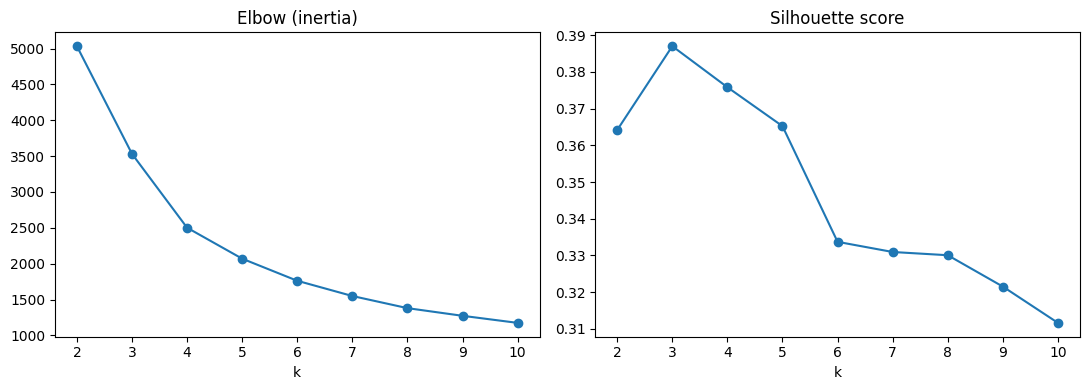

In [38]:
ks = list(range(2, 11))
inertias, sils = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))
    print(k, round(km.inertia_, 1), round(sils[-1], 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertias, marker='o'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(ks, sils, marker='o');     ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

FIT K-MEANS (k=4) AND PROFILE THE CLUSTERS

In [39]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
df['cluster'] = km.labels_

profile = (df.groupby('cluster')
             .agg(customers=('customer_id', 'size'),
                  avg_recency=('recency_days', 'mean'),
                  avg_frequency=('frequency', 'mean'),
                  avg_monetary=('monetary', 'mean'))
             .round(1))
print(profile)
print()


         customers  avg_recency  avg_frequency  avg_monetary
cluster                                                     
0              655         26.6           13.7      118185.0
1              558         19.4            2.2        9060.9
2             1119        161.7            5.8       39759.5
3              630        536.4            1.8        5833.3



In [40]:
print(pd.crosstab(df['segment'], df['cluster']))

cluster                0    1    2    3
segment                                
At Risk                6    0  546  135
Champions            478    0   41    0
Hibernating            0    0    8   65
Lost                   0    0    4  418
Loyal                166   41  261    0
Needs Attention        0   45  180   12
New Customers          0  192    0    0
Potential Loyalists    5  280   79    0


ADD CLUSTER NAMES AND DOWNLOAD

In [41]:
names = {0: 'High-value regulars',
         1: 'Recent light buyers',
         2: 'Mid-value, cooling',
         3: 'Gone, low-value'}
df['cluster_name'] = df['cluster'].map(names)

print(df.shape)
print(df['cluster_name'].value_counts())

df.to_csv('rfm_clusters.csv', index=False)
files.download('rfm_clusters.csv')

(2962, 10)
cluster_name
Mid-value, cooling     1119
High-value regulars     655
Gone, low-value         630
Recent light buyers     558
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>